# Do customers judge OPPO on the experience or on the hardware?
**Python Applied to Business · Group project · Group Xie Xie**

**Recommendation we test.** Our Business Strategy plan said OPPO's unique point should come *"from their AI-led operation and less from their hardware features"*.

**Operational question.** What drives OPPO's 1–2 star reviews, hardware or the software experience, and what should OPPO fix first?

**Data.** 45,280 Flipkart (India) reviews of OPPO, Vivo, Redmi and iPhone phones, 2013–2017 (Sheikh, 2021, Mendeley Data, CC BY 4.0). Put `oppo.csv`, `vivo.csv`, `redmi.csv` and `iphone.csv` next to this notebook.



## Setup

In [1]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

BRANDS = {"oppo": "OPPO", "vivo": "Vivo", "redmi": "Redmi", "iphone": "iPhone"}
DATA = next(p for p in [Path("data"), Path(".")] if (p / "oppo.csv").is_file())
COLUMNS = ["user_name", "user_id", "product", "product_id", "rating", "title", "review", "upvotes", "downvotes", "date"]
raw = pd.concat([pd.read_csv(DATA / f"{b}.csv", header=None, names=COLUMNS).assign(brand=b) for b in BRANDS], ignore_index=True)

BLUE, GREY, ORANGE, GREEN, INK = "#2a78d6", "#b5b4ae", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.axisbelow": True, "axes.titleweight": "bold", "font.size": 9.5})
print(f"{len(raw):,} reviews loaded")

45,283 reviews loaded


## 1. Cleaning
Decisions:
- Drop duplicate reviews and the web-page text "READ MORE".
- A **negative review** is 1 or 2 stars.
- **Use the review text only, not the title.** Flipkart offers ready-made titles that match the stars ("Waste of money!" for 1 star, "Worth every penny" for 5), so titles repeat the rating instead of explaining it. The check below shows it.

In [2]:
reviews = raw.drop_duplicates(["user_id", "product_id", "review"]).copy()
reviews["text"] = reviews["review"].fillna("").str.replace("READ MORE", "", regex=False).str.replace(r"\s+", " ", regex=True).str.strip().str.lower()
reviews["words"] = reviews["text"].str.split().str.len()
reviews["negative"] = (reviews["rating"] <= 2).astype(int)
reviews["date"] = pd.to_datetime(reviews["date"], format="%d-%b-%y")
reviews["model"] = reviews["product"].str.replace(r"\s*\(.*$", "", regex=True).str.strip()

common_titles = reviews["title"].value_counts()
common_titles = common_titles[common_titles >= 200].index
print(f"Duplicates dropped: {len(raw) - len(reviews)}   Reviews kept: {len(reviews):,}")
print(f"Reviews using a ready-made title: {reviews['title'].isin(common_titles).mean():.0%}")
print(reviews[reviews["title"].isin(["Waste of money!", "Worth every penny", "Terrific purchase"])]
      .groupby("title")["rating"].mean().round(2).to_string())

Duplicates dropped: 3   Reviews kept: 45,280
Reviews using a ready-made title: 65%
title
Terrific purchase    4.98
Waste of money!      1.15
Worth every penny    4.94


## 2. Exploratory analysis
How often does each brand get a 1–2 star review? Vivo is OPPO's sister brand (same parent company, similar phones and prices in India).

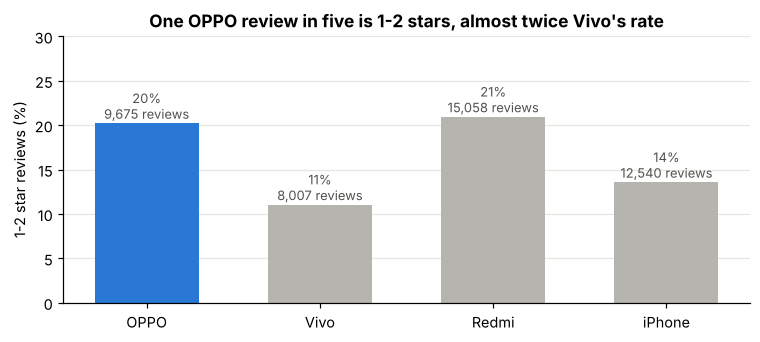

In [3]:
by_brand = reviews.groupby("brand")["negative"].agg(["size", "mean"]).loc[list(BRANDS)]
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar([BRANDS[b] for b in by_brand.index], 100 * by_brand["mean"], width=0.6,
              color=[BLUE if b == "oppo" else GREY for b in by_brand.index])
for bar, (n, rate) in zip(bars, by_brand.itertuples(index=False)):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5, f"{rate:.0%}\n{n:,} reviews", ha="center", fontsize=8.5, color=INK)
ax.set_ylim(0, 30); ax.set_ylabel("1-2 star reviews (%)"); ax.grid(axis="x", visible=False)
ax.set_title("One OPPO review in five is 1-2 stars, almost twice Vivo's rate")
plt.tight_layout(); plt.show()

Within OPPO, one model stands out. The chart follows the OPPO F3 month by month against all other OPPO models, with a simple alarm a quality team could run every month: *flag a model whose share of bad reviews is more than twice the brand average*.

               reviews  negative
model                           
OPPO F3            810      0.55
OPPO Neo 7 4G      896      0.27
OPPO F3 Plus      1150      0.19
OPPO F1s          2770      0.17
OPPO F1 Plus       547      0.15
OPPO F1            307      0.14
OPPO A37f         1180      0.13
OPPO A57          1720      0.12


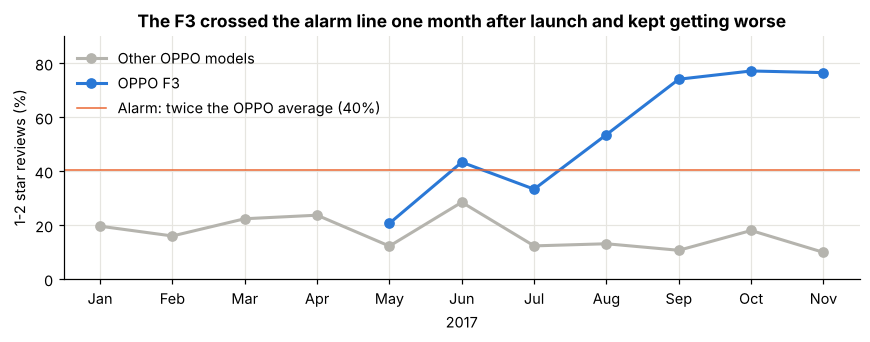

The alarm would have flagged the F3 in June 2017; by October 77% of its reviews were 1-2 stars.


In [4]:
oppo = reviews[reviews["brand"] == "oppo"].copy()
print(oppo.groupby("model")["negative"].agg(reviews="size", negative="mean").query("reviews >= 300")
      .sort_values("negative", ascending=False).round(2).to_string())

recent = oppo[oppo["date"] >= "2017-01-01"].assign(month=lambda d: d["date"].dt.to_period("M"))
f3 = recent[recent["model"] == "OPPO F3"].groupby("month")["negative"].agg(["size", "mean"])
others = recent[recent["model"] != "OPPO F3"].groupby("month")["negative"].mean()
alarm_line = 2 * oppo["negative"].mean()
first_alarm = f3[(f3["size"] >= 50) & (f3["mean"] > alarm_line)].index[0]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot([m.strftime("%b") for m in others.index], 100 * others, color=GREY, marker="o", linewidth=2, label="Other OPPO models")
ax.plot([m.strftime("%b") for m in f3.index], 100 * f3["mean"], color=BLUE, marker="o", linewidth=2, label="OPPO F3")
ax.axhline(100 * alarm_line, color=ORANGE, linewidth=1, label=f"Alarm: twice the OPPO average ({alarm_line:.0%})")
ax.set_ylim(0, 90); ax.set_ylabel("1-2 star reviews (%)"); ax.set_xlabel("2017"); ax.legend(frameon=False, loc="upper left")
ax.set_title("The F3 crossed the alarm line one month after launch and kept getting worse")
plt.tight_layout(); plt.show()
print(f"The alarm would have flagged the F3 in {first_alarm.strftime('%B %Y')}; by October {f3.loc['2017-10', 'mean']:.0%} of its reviews were 1-2 stars.")

## 3. What do bad reviews talk about?
We tag each review with the topics it mentions, using word patterns, and group them the way our plan frames the question: **hardware**, **software & experience** (what the plan says OPPO should compete on) and **value & service**. A mention is not always a complaint ("great camera"), so section 4 measures which topics go with bad ratings.

In [5]:
ASPECTS = {
    "battery":       ("Hardware", r"\bbatter(?:y|ies)\b|\bbackup\b|\bdrain|\bmah\b"),
    "heating":       ("Hardware", r"\bheat|\bhot\b|\bwarm\b|\btemperature"),
    "camera":        ("Hardware", r"\bcam(?:era)?s?\b|\bselfie|\bphotos?\b|\bpics?\b|\bpictures?\b|\bmp\b|\bmegapixel"),
    "display":       ("Hardware", r"\bdisplay|\bscreen|\bresolution|\bbrightness|\b720p|\bhd\b"),
    "charging":      ("Hardware", r"\bcharg(?:e|er|ers|ing)\b|\bvooc\b"),
    "sound & calls": ("Hardware", r"\bsound|\bspeaker|\baudio|\bvolume|\bear ?phones?|\bheadphones?|\bmic\b|\bcall quality|\bvoice"),
    "network":       ("Hardware", r"\bnetwork|\bsignal|\bsims?\b|\b4g\b|\bvolte\b|\bjio\b|\bwi-?fi|\bbluetooth|\bgps\b|\bcall drop"),
    "build":         ("Hardware", r"\bbuild\b|\bdesign|\bbody\b|\bmetal|\bslim|\bplastic|\bscratch|\bgorilla|\bglass\b"),
    "faulty unit":   ("Hardware", r"\bdefect|\bfaulty|\bdamaged? (?:piece|phone|product|unit|mobile)|\bdead\b|\bnot working|\bstopped working|\bnot (?:switch|turn)(?:ing)? on|\bswitch(?:ed|es)? off"),
    "storage & RAM": ("Hardware", r"\bram\b|\bstorage|\bmemory|\binternal space|\bsd card"),
    "software & UI": ("Software & experience", r"\bcolou?r ?os\b|\bui\b|\binterface|\blauncher|\bsoftware|\boperating system|\btheme"),
    "updates":       ("Software & experience", r"\bupdat|\bupgrad|\bmarshmallow|\bnougat|\blollipop|\bkitkat|\bandroid (?:version|[4-8](?:\.\d)?)\b"),
    "lag & speed":   ("Software & experience", r"\bhang|\blag|\bslow|\bstuck|\bfreez|\bsmooth|\bperformance|\bspeed\b|\bmulti ?task"),
    "apps & bugs":   ("Software & experience", r"\bbugs?\b|\bcrash|\bglitch|\breboot|\brestart|\bbloat|\bapps?\b|\bnotification|\bwhatsapp"),
    "price & value": ("Value & service", r"\bprice|\bcost|\bworth|\bvalue\b|\bmoney\b|\bexpensive|\boverpriced|\bcheap|\bbudget|\brs\.?\s?\d|\b\d+k\b"),
    "service":       ("Value & service", r"\bservice cent|\bcustomer (?:care|service|support)|\bwarranty|\brepair|\breplace|\brefund|\breturn"),
    "delivery":      ("Value & service", r"\bdeliver|\bflipkart|\bseller|\bpackag|\bcourier|\bfake\b|\bduplicate|\bsecond hand"),
}
GROUPS = ["Hardware", "Software & experience", "Value & service"]
for aspect, (group, pattern) in ASPECTS.items():
    reviews[aspect] = reviews["text"].str.contains(pattern, regex=True).astype(int)
for group in GROUPS:
    reviews[group] = reviews[[a for a, (g, _) in ASPECTS.items() if g == group]].max(axis=1)
oppo = reviews[reviews["brand"] == "oppo"].copy()
oppo_bad = oppo[oppo["negative"] == 1]
print(f"OPPO 1-2 star reviews: {len(oppo_bad):,}")
print(oppo_bad[GROUPS].mean().map("{:.0%}".format).to_string())
software_without_lag = oppo_bad[["software & UI", "updates", "apps & bugs"]].max(axis=1).mean()
print(f"Software & experience without 'lag & speed': {software_without_lag:.0%}")
print(f"Bad reviews that name no topic at all: {1 - oppo_bad[list(ASPECTS)].max(axis=1).mean():.0%}")

OPPO 1-2 star reviews: 1,957
Hardware                 53%
Software & experience    21%
Value & service          30%
Software & experience without 'lag & speed': 8%
Bad reviews that name no topic at all: 29%


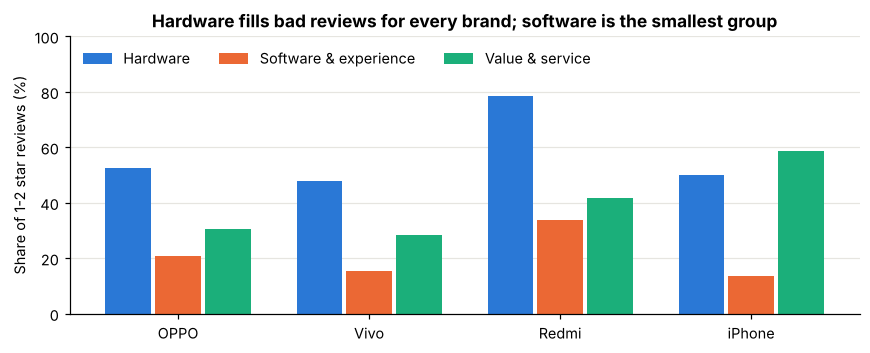

In [6]:
mix = reviews[reviews["negative"] == 1].groupby("brand")[GROUPS].mean().loc[list(BRANDS)]
fig, ax = plt.subplots(figsize=(8, 3.3))
for j, (g, colour) in enumerate(zip(GROUPS, [BLUE, ORANGE, GREEN])):
    ax.bar(np.arange(4) + (j - 1) * 0.26, 100 * mix[g], width=0.24, color=colour, label=g)
ax.set_xticks(range(4), [BRANDS[b] for b in mix.index]); ax.grid(axis="x", visible=False)
ax.set_ylabel("Share of 1-2 star reviews (%)"); ax.set_ylim(0, 100); ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("Hardware fills bad reviews for every brand; software is the smallest group")
plt.tight_layout(); plt.show()

## 4. Model: what drives a 1–2 star review?
As in Session 4, we train on earlier reviews (before July 2017) and test on later ones (July–November 2017). Inputs: the 17 topic tags, the review length (unhappy buyers write more, so we control for it) and the phone model. We compare a logistic regression with gradient boosting and a baseline that always predicts "not negative".

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

oppo["log_words"] = np.log1p(oppo["words"])
NUMERIC = list(ASPECTS) + ["log_words"]
train, test = oppo[oppo["date"] < "2017-07-01"], oppo[oppo["date"] >= "2017-07-01"]
prepare = lambda scale: ColumnTransformer([("model", OneHotEncoder(handle_unknown="ignore", min_frequency=100), ["model"]),
                                           ("numbers", StandardScaler() if scale else "passthrough", NUMERIC)])
models = {"Logistic regression": Pipeline([("prep", prepare(True)), ("clf", LogisticRegression(max_iter=3000))]),
          "Gradient boosting": Pipeline([("prep", prepare(False)), ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, random_state=2026))])}
rows = [{"model": "Baseline: always 'not negative'", "accuracy": 1 - test["negative"].mean(), "AUC": 0.5}]
for name, m in models.items():
    m.fit(train[NUMERIC + ["model"]], train["negative"])
    p = m.predict_proba(test[NUMERIC + ["model"]])[:, 1]
    rows.append({"model": name, "accuracy": accuracy_score(test["negative"], p >= 0.5), "AUC": roc_auc_score(test["negative"], p)})
print(f"Train: {len(train):,} reviews before July 2017 · Test: {len(test):,} reviews July-November 2017")
results = pd.DataFrame(rows).set_index("model").round(3)
results

Train: 5,942 reviews before July 2017 · Test: 3,733 reviews July-November 2017


,accuracy,AUC
model,,
Baseline: always 'not negative',0.790,0.500
Logistic regression,0.806,0.761
Gradient boosting,0.806,0.762


Both models rank bad reviews far better than chance (AUC about 0.76) and agree with each other, so we read the simpler one. The **odds ratio** of a topic says how much mentioning it multiplies the odds that a review is 1–2 stars, everything else equal (fitted on all OPPO reviews with `statsmodels` to get 95% intervals). Above 1 is a pain point; below 1 a strength; an interval crossing 1 means no clear effect.

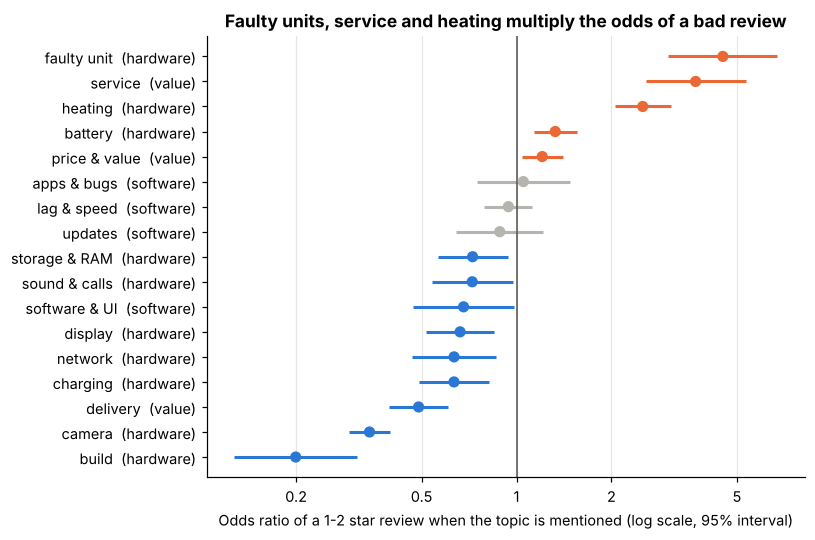

,odds ratio,low,high
faulty unit,4.51,3.03,6.72
service,3.70,2.57,5.33
heating,2.51,2.05,3.09
battery,1.33,1.13,1.55
price & value,1.21,1.04,1.40
apps & bugs,1.05,0.75,1.47
lag & speed,0.94,0.79,1.12
updates,0.88,0.64,1.22
storage & RAM,0.73,0.56,0.94
sound & calls,0.72,0.54,0.97


In [8]:
import statsmodels.api as sm
fit = sm.Logit(oppo["negative"], sm.add_constant(oppo[NUMERIC].astype(float))).fit(disp=0)
odds = pd.DataFrame({"odds ratio": np.exp(fit.params), "low": np.exp(fit.conf_int()[0]), "high": np.exp(fit.conf_int()[1])}).loc[list(ASPECTS)]
odds = odds.sort_values("odds ratio")
colour = np.where(odds["low"] > 1, ORANGE, np.where(odds["high"] < 1, BLUE, GREY))

fig, ax = plt.subplots(figsize=(7.5, 5))
y = np.arange(len(odds))
ax.hlines(y, odds["low"], odds["high"], color=colour, linewidth=2)
ax.scatter(odds["odds ratio"], y, color=colour, s=40, zorder=3)
ax.axvline(1, color=INK, linewidth=1)
ax.set_xscale("log"); ax.set_xticks([0.2, 0.5, 1, 2, 5], ["0.2", "0.5", "1", "2", "5"]); ax.minorticks_off()
ax.set_yticks(y, [f"{a}  ({ASPECTS[a][0].split()[0].lower()})" for a in odds.index]); ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds ratio of a 1-2 star review when the topic is mentioned (log scale, 95% interval)")
ax.set_title("Faulty units, service and heating multiply the odds of a bad review")
plt.tight_layout(); plt.show()
odds.round(2).iloc[::-1]

## 5. Decision
**What the evidence says about our plan.** Customers judge OPPO on hardware. The camera is its biggest strength; heating, battery and faulty units are its biggest pain points, together with after-sales service. Software, UI and updates are rarely mentioned and do not raise the odds of a bad review. The evidence does **not** support "less from hardware"; it supports "protect the core".

**What OPPO's operations teams should do first**
1. **Quality and suppliers:** add heating and battery-drain stress tests at the end of the production line and audit battery suppliers.
2. **Manufacturing and after-sales:** tighten outgoing inspection and replace faulty phones without a service-centre visit.
3. **Quality analytics:** run the monthly alarm from section 2 on every model; it would have caught the F3 in June 2017.
4. **AI team:** use AI first inside operations (this kind of review monitoring) before making it the main thing OPPO sells.

**Limits.** Reviews are from 2014–2017, before OPPO's AI features, so we test the premise (do buyers judge OPPO on hardware or experience?), not the AI features. One channel and market (Flipkart, India). Word patterns miss negation and sarcasm. The odds ratios are associations, not proof of cause.

## References
Sheikh, A. (2021). *opinions Dataset* (Version 1) [Data set]. Mendeley Data. https://doi.org/10.17632/wzxkx2kr6n.1

Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*.